In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteCaloriesNarrow_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/weightLogInfo_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteMETsNarrow_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyCalories_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/heartrate_seconds_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteSleep_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyIntensities_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitaba

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import datetime as dt

import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv')

daily_activity = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv')
daily_sleep = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv')
hourly_steps = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/hourlySteps_merged.csv')

print("Activity rows and columns:", daily_activity.shape)
print("Sleep rows and columns:", daily_sleep.shape)
print("Steps rows and columns:", hourly_steps.shape)

Activity rows and columns: (940, 15)
Sleep rows and columns: (413, 5)
Steps rows and columns: (22099, 3)


In [4]:
# Preview the first five rows of each dataset
display(daily_activity.head())
display(daily_sleep.head())
display(hourly_steps.head())

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,4/12/2016,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1,1503960366,4/13/2016,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
2,1503960366,4/14/2016,10460,6.74,6.74,0.0,2.44,0.40,3.91,0.0,30,11,181,1218,1776
3,1503960366,4/15/2016,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
4,1503960366,4/16/2016,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


,Id,ActivityHour,StepTotal
0,1503960366,4/12/2016 12:00:00 AM,373
1,1503960366,4/12/2016 1:00:00 AM,160
2,1503960366,4/12/2016 2:00:00 AM,151
3,1503960366,4/12/2016 3:00:00 AM,0
4,1503960366,4/12/2016 4:00:00 AM,0


In [5]:
# Check data quality
print("Activity missing values:", daily_activity.isna().sum().sum())
print("Sleep missing values:", daily_sleep.isna().sum().sum())
print("Hourly steps missing values:", hourly_steps.isna().sum().sum())

print("Activity duplicate rows:", daily_activity.duplicated().sum())
print("Sleep duplicate rows:", daily_sleep.duplicated().sum())
print("Hourly steps duplicate rows:", hourly_steps.duplicated().sum())

print("Activity participants:", daily_activity["Id"].nunique())
print("Sleep participants:", daily_sleep["Id"].nunique())
print("Hourly steps participants:", hourly_steps["Id"].nunique())

Activity missing values: 0
Sleep missing values: 0
Hourly steps missing values: 0
Activity duplicate rows: 0
Sleep duplicate rows: 3
Hourly steps duplicate rows: 0
Activity participants: 33
Sleep participants: 24
Hourly steps participants: 33


In [6]:
# Create working copies so the original data remains unchanged
activity_clean = daily_activity.copy()
sleep_clean = daily_sleep.copy()
hourly_steps_clean = hourly_steps.copy()

# Convert the date and hour columns into true date and hour values
activity_clean["ActivityDate"] = pd.to_datetime(activity_clean["ActivityDate"],format="%m/%d/%Y")

sleep_clean["SleepDay"] = pd.to_datetime(sleep_clean["SleepDay"],format="%m/%d/%Y %I:%M:%S %p"
).dt.normalize()

hourly_steps_clean["ActivityHour"] = pd.to_datetime(hourly_steps_clean["ActivityHour"]
)

# Give both date columns the same name
activity_clean = activity_clean.rename(columns={"ActivityDate": "Date"})
sleep_clean = sleep_clean.rename(columns={"SleepDay": "Date"})

# Remove exact duplicate sleep records
sleep_clean = sleep_clean.drop_duplicates().reset_index(drop=True)

# Verify the results
print("Clean activity rows:", len(activity_clean))
print("Clean sleep rows:", len(sleep_clean))
print("Remaining sleep duplicates:", sleep_clean.duplicated().sum())
print("Activity dates:", activity_clean["Date"].min(), "to", activity_clean["Date"].max())
print("Sleep dates:", sleep_clean["Date"].min(), "to", sleep_clean["Date"].max())

Clean activity rows: 940
Clean sleep rows: 410
Remaining sleep duplicates: 0
Activity dates: 2016-04-12 00:00:00 to 2016-05-12 00:00:00
Sleep dates: 2016-04-12 00:00:00 to 2016-05-12 00:00:00


In [7]:
activity_clean["TotalActiveMinutes"] = (
    activity_clean["VeryActiveMinutes"]
    + activity_clean["FairlyActiveMinutes"]
    + activity_clean["LightlyActiveMinutes"]
)

activity_clean["DayOfWeek"] = activity_clean["Date"].dt.day_name()
sleep_clean["SleepHours"] = sleep_clean["TotalMinutesAsleep"] / 60
sleep_clean["TimeInBedHours"] = sleep_clean["TotalTimeInBed"] / 60
sleep_clean["SleepEfficiency"] = (
    sleep_clean["TotalMinutesAsleep"] / sleep_clean["TotalTimeInBed"] * 100
)

In [8]:
# Merge matching activity and sleep records
activity_sleep_merged = pd.merge(
    activity_clean,
    sleep_clean,
    on=["Id", "Date"],
    how="inner",
    validate="one_to_one"
)

# Verify the merged dataset
print("Merged rows and columns:", activity_sleep_merged.shape)
print("Participants in merged data:", activity_sleep_merged["Id"].nunique())
print("Missing values:", activity_sleep_merged.isna().sum().sum())

display(activity_sleep_merged.head())

Merged rows and columns: (410, 23)
Participants in merged data: 24
Missing values: 0


,Id,Date,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,...,SedentaryMinutes,Calories,TotalActiveMinutes,DayOfWeek,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed,SleepHours,TimeInBedHours,SleepEfficiency
0,1503960366,2016-04-12,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,...,728,1985,366,Tuesday,1,327,346,5.450000,5.766667,94.508671
1,1503960366,2016-04-13,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,...,776,1797,257,Wednesday,2,384,407,6.400000,6.783333,94.348894
2,1503960366,2016-04-15,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,...,726,1745,272,Friday,1,412,442,6.866667,7.366667,93.212670
3,1503960366,2016-04-16,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,...,773,1863,267,Saturday,2,340,367,5.666667,6.116667,92.643052
4,1503960366,2016-04-17,9705,6.48,6.48,0.0,3.19,0.78,2.51,0.0,...,539,1728,222,Sunday,1,700,712,11.666667,11.866667,98.314607


In [9]:
#Activity Categories

activity_clean["ActivityCategory"] = pd.cut(
    activity_clean["TotalSteps"],
    bins=[0, 5000, 10000, float("inf")],
    labels=["Low Activity", "Moderate Activity", "High Activity"]
)

In [10]:
activity_summary = activity_clean.groupby(
    "ActivityCategory",
    observed=True
)[[
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]].mean()

sleep_summary = sleep_clean[
    [
        "SleepHours",
        "TimeInBedHours",
        "SleepEfficiency"
    ]
].agg(["mean", "median", "min", "max"]).round(1).T

print("Activity Summary")
display(activity_summary)

print("Sleep Summary")
display(sleep_summary)

Activity Summary


,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes
ActivityCategory,,,,
Low Activity,2.986726,2.646018,118.269912,1045.203540
Moderate Activity,13.407186,11.553892,246.850299,956.092814
High Activity,48.544554,27.372937,237.844884,888.660066


Sleep Summary


,mean,median,min,max
SleepHours,7.0,7.2,1.0,13.3
TimeInBedHours,7.6,7.7,1.0,16.0
SleepEfficiency,91.6,94.3,49.8,100.0


In [11]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]
weekday_sleep = (
    activity_sleep_merged.groupby("DayOfWeek")
    .agg(
        AverageSleepHours=("SleepHours", "mean"),
        AverageSleepEfficiency=("SleepEfficiency", "mean"),
        AverageSteps=("TotalSteps", "mean")
    )
    .reindex(day_order)
    .round(1)
)

display(weekday_sleep)

,AverageSleepHours,AverageSleepEfficiency,AverageSteps
DayOfWeek,,,
Monday,7.0,92.0,9273.2
Tuesday,6.7,91.1,9182.7
Wednesday,7.2,92.1,8022.9
Thursday,6.7,92.3,8183.5
Friday,6.8,92.0,7901.4
Saturday,7.0,91.5,9871.1
Sunday,7.5,90.5,7297.9


In [12]:
# Extract day of week for hourly_steps_clean
hourly_steps_clean["DayOfWeek"] = (hourly_steps_clean["ActivityHour"].dt.day_name())

# Extract hour
hourly_steps_clean["Hour"] = (hourly_steps_clean["ActivityHour"].dt.hour)

**Does physical activity translate into higher calorie expenditure?**

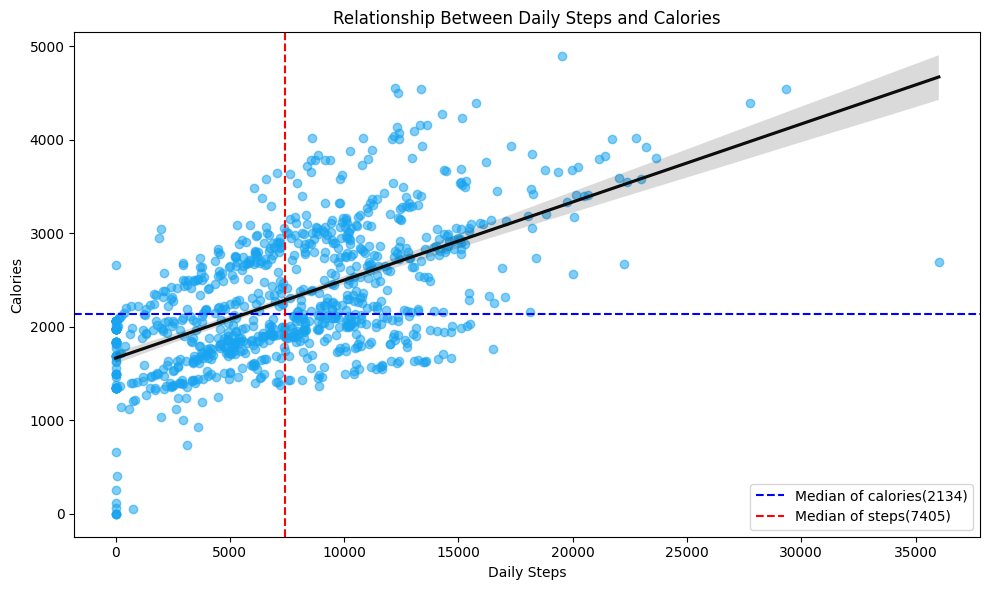

In [13]:
# Scatterplot of Calories and Total steps

plt.figure(figsize=(10, 6))

median_steps = 7405
median_calories = 2134

plt.axhline(median_calories,color = 'b', linestyle = '--', label = f'Median of calories({median_calories})')
plt.axvline(median_steps,color = 'r', linestyle = '--', label = f'Median of steps({median_steps})')

sns.regplot(
    data=activity_clean,
    x="TotalSteps",
    y="Calories",
    scatter_kws={"alpha": 0.55, "color": "#18a4f0"},
    line_kws={"color": "#0c0c0d"}
)

plt.title("Relationship Between Daily Steps and Calories")
plt.xlabel("Daily Steps")
plt.ylabel("Calories")

plt.legend()
plt.tight_layout()

plt.show()

**Are users who get more sleep also more physically active?**

In [ ]:
# Relationship between Sleep and Activity

plt.figure(figsize=(10, 6))

sns.regplot(
    data=activity_sleep_merged,
    x="TotalSteps",
    y="SleepHours",
    scatter_kws={'alpha': 0.55},
    line_kws={'color': 'black'}
)

plt.title("Relationship Between Daily Steps and Sleep Duration")
plt.xlabel("Daily Steps")
plt.ylabel("Sleep Duration (Hours)")

plt.tight_layout()
plt.show()

**Are highly sedentary users also taking fewer steps?**

In [ ]:
# Relationship between Sedentary Time and Total Steps
plt.figure(figsize=(10, 6))

sns.regplot(
    data=activity_clean,
    x="SedentaryMinutes",
    y="TotalSteps",
    scatter_kws={'alpha': 0.55, 'color': '#18a4f0'},
    line_kws={'color': '#0c0c0d'}
)

plt.title("Relationship Between Sedentary Time and Daily Steps")
plt.xlabel("Sedentary Minutes")
plt.ylabel("Total Steps")

plt.tight_layout()
plt.show()

**How does different activity level users spend time in different activity types?**

In [ ]:
activity_summary.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Activity Patterns by User Activity Level")
plt.xlabel("Activity Category")
plt.ylabel("Average Minutes")
plt.xticks(rotation=0)
plt.legend(title="Activity Type")

plt.tight_layout()
plt.show()

**Which days are users most and least active?**

In [ ]:
#average steps per day
steps_by_day = activity_clean.groupby(
    "DayOfWeek"
)["TotalSteps"].mean()

print(steps_by_day)

In [ ]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

steps_by_day = (
    activity_clean
    .groupby("DayOfWeek")["TotalSteps"]
    .mean()
    .reindex(day_order)
)

In [ ]:
#Activity by Day of Week

plt.figure(figsize=(10, 6))

steps_by_day.plot(kind="bar")

plt.title("Average Daily Steps by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Total Steps")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**How much time are users spending in bed without sleeping ?**

In [ ]:
# Relationship Between Time in Bed and Sleep Efficiency

plt.figure(figsize=(10, 6))

sns.regplot(
    data=sleep_clean,
    x="TotalTimeInBed",
    y="SleepEfficiency",
    scatter_kws={'alpha': 0.55, 'color': '#18a4f0'},
    line_kws={'color': '#0c0c0d'}
)

plt.title("Relationship Between Time in Bed and Sleep Efficiency")
plt.xlabel("Total Time in Bed (Minutes)")
plt.ylabel("Sleep Efficiency (%)")

plt.tight_layout()
plt.show()

**Do Users sleep different in different days ?**

In [ ]:
# Relationship btw average sleep hours and day of the week
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weekday_sleep.index,
    y=weekday_sleep["AverageSleepHours"],
    color="#0911E8"
)

plt.axhline(
    sleep_clean["SleepHours"].mean(),
    color="#444444",
    linestyle="--",
    label="Overall sleep average"
)

plt.title("Average Sleep Duration by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sleep Hours")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()


plt.show()

**When Are Users Most Active?**

In [ ]:
hourly_steps_clean["DayOfWeek"] = (
    hourly_steps_clean["ActivityHour"].dt.day_name()
)

hourly_steps_clean["Hour"] = (
    hourly_steps_clean["ActivityHour"].dt.hour
)

In [ ]:
heatmap_data = hourly_steps_clean.pivot_table(
    index="DayOfWeek",
    columns="Hour",
    values="StepTotal",
    aggfunc="mean"
)

In [ ]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    cmap="Blues"
)

plt.title("Average Steps by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

**Correlation Heatmap**

In [ ]:
correlation_columns = [
    "TotalSteps",
    "TotalDistance",
    "Calories",
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]

correlation_matrix = activity_clean[
    correlation_columns
].corr()

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Activity and Calorie Variables")

plt.tight_layout()
plt.show()

In [ ]:
# correlation heatmap
correlation_table = activity_sleep_merged[
    [
        "TotalSteps",
        "TotalActiveMinutes",
        "SedentaryMinutes",
        "SleepHours",
        "SleepEfficiency"
    ]
].corr().round(2)
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_table,
    annot=True,
    cmap="PuBu",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
     linewidths=0.5
)

plt.title("Relationships Between Activity and Sleep Measures")
plt.tight_layout()

plt.show()